# 02 · Modeling, Tuning & Evaluation — Building Energy Efficiency

**Đồ án môn Học máy (608807) — Nhóm 01**

Notebook này thực hiện 4 phần còn lại của quy trình: thử nghiệm đa mô hình, Cross-Validation & Tuning,
đánh giá chuyên sâu + Error Analysis, và đóng gói mô hình.

---

## Giao thức đánh giá (cam kết thực hiện đúng)

| Nguyên tắc | Cách thực hiện trong notebook |
|---|---|
| Chia train/test **trước** mọi bước học tham số | Dùng lại `results/split_indices.json` của notebook 01 |
| Không rò rỉ dữ liệu | Mọi imputer/scaler/encoder nằm **trong** `Pipeline` |
| Test chỉ dùng **một lần** | Toàn bộ CV/Tuning chạy trên `X_train`; bảng test ở mục 7 là lần duy nhất |
| Tái lập | `random_state = 42`, K-Fold có shuffle + seed |
| Không chọn mô hình bằng test | Mô hình tốt nhất chọn theo **CV R²**, test chỉ để *báo cáo* |

In [1]:
import sys, json, time, warnings, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings("ignore")

NB_DIR = Path.cwd()
ROOT = NB_DIR.parent if (NB_DIR.parent / "data").exists() else NB_DIR
FIG_DIR = ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)
RES_DIR = ROOT / "results"; RES_DIR.mkdir(exist_ok=True)
MODEL_DIR = ROOT / "models"; MODEL_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT))

from src.features import (RANDOM_STATE, CV_FOLDS, TARGETS, TARGET_NAMES,
                          FEATURE_COLS, build_features, make_preprocessor)
from src.evaluation import (regression_metrics, cross_validate_multioutput,
                            summarize_cv, timed_fit_predict)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150,
                     "font.family": "DejaVu Sans", "axes.titlesize": 11,
                     "axes.titleweight": "bold", "figure.autolayout": True})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 80)

SEED = RANDOM_STATE
print("ROOT:", ROOT)

ROOT: D:\MCLN\Nhom01_608807_BuildingEnergyEfficiency\03_SourceCode


## 1. Nạp lại đúng tập train/test của notebook 01

In [2]:
df = pd.read_excel(ROOT / "data" / "ENB2012_data.xlsx")
df_fe = build_features(df)

split = json.loads((RES_DIR / "split_indices.json").read_text(encoding="utf-8"))
idx_train = np.array(split["idx_train"])
idx_test = np.array(split["idx_test"])

X_train = df_fe.iloc[idx_train][FEATURE_COLS]
y_train = df.iloc[idx_train][TARGETS]
X_test = df_fe.iloc[idx_test][FEATURE_COLS]
y_test = df.iloc[idx_test][TARGETS]

fingerprint = hashlib.md5(",".join(map(str, sorted(idx_test))).encode()).hexdigest()[:10]
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Fingerprint tập test: {fingerprint}  (ghi vào báo cáo để chứng minh dùng đúng 1 tập test)")

from sklearn.model_selection import KFold
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

Train: (614, 19) | Test: (154, 19)
Fingerprint tập test: e48f1962cd  (ghi vào báo cáo để chứng minh dùng đúng 1 tập test)


**Vì sao phải in "fingerprint"?** Trong báo cáo khoa học, khi công bố kết quả trên một tập test,
ta cần chứng minh **đúng tập test đó** được dùng cho mọi mô hình và không bị chỉnh sửa.
Mã băm 10 ký tự ở trên là "dấu vân tay" của 154 chỉ số dòng test.

## 2. Ba chiến lược cho bài toán đa mục tiêu

Đề bài yêu cầu nêu rõ chiến lược và **so sánh**. Ta so sánh 6 cấu hình trên cùng giao thức 5-Fold:

| # | Chiến lược | Cơ chế |
|---|---|---|
| 1 | **Hai mô hình riêng** | Mỗi mục tiêu một Pipeline độc lập (Ridge) |
| 2 | **MultiOutputRegressor** | Bọc 1 mô hình đơn ra, sklearn tự nhân bản cho từng mục tiêu |
| 3 | **RegressorChain** | Mô hình Y1 trước, rồi dùng dự đoán Y1 làm đặc trưng cho Y2 |
| 4 | **Native multi-output** | Mô hình hỗ trợ đa đầu ra gốc (XGBoost `multi_strategy`) |
| 5 | **MultiOutput(XGB)** | Bọc XGBoost đơn ra (để so sánh với native) |
| 6 | **RegressorChain(XGB)** | Chain với mô hình mạnh nhất |

Với Ridge, chiến lược 1 và 2 **về lý thuyết là tương đương** (mỗi mục tiêu học độc lập) — ta kiểm chứng bằng số.

In [3]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import Ridge
from sklearn.multioutput import MultiOutputRegressor, RegressorChain
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

class SeparateTargetRegressor(BaseEstimator, RegressorMixin):
    # Chiến lược 'hai mô hình riêng': factory() tạo một pipeline mới cho mỗi mục tiêu.
    # Viết dưới dạng estimator để dùng lại được cross_validate_multioutput().
    def __init__(self, factory=None):
        self.factory = factory

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.models_ = [self.factory().fit(X, y[:, j]) for j in range(y.shape[1])]
        return self

    def predict(self, X):
        return np.column_stack([m.predict(X) for m in self.models_])


def ridge_pipe():
    # Pipeline Ridge cho 1 mục tiêu (alpha rất nhỏ vì dữ liệu gần như không nhiễu)
    return Pipeline([("prep", make_preprocessor(scale=True)), ("model", Ridge(alpha=1e-4))])


def xgb_pipe():
    # Pipeline XGBoost cấu hình mặc định hợp lý (sẽ được tuning ở mục 4)
    return Pipeline([("prep", make_preprocessor(scale=False)),
                     ("model", XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                                            subsample=0.9, colsample_bytree=0.9,
                                            random_state=SEED, n_jobs=2))])


strategies = {
    "1. Hai mô hình riêng (Ridge)": SeparateTargetRegressor(ridge_pipe),
    "2. MultiOutputRegressor (Ridge)": Pipeline([("prep", make_preprocessor()),
                                                 ("model", MultiOutputRegressor(Ridge(alpha=1e-4)))]),
    "3. RegressorChain (Ridge)": Pipeline([("prep", make_preprocessor()),
                                           ("model", RegressorChain(Ridge(alpha=1e-4)))]),
    "4. XGBoost native đa đầu ra": xgb_pipe(),
    "5. MultiOutputRegressor (XGB)": Pipeline([("prep", make_preprocessor(scale=False)),
                                               ("model", MultiOutputRegressor(
                                                   XGBRegressor(n_estimators=400, learning_rate=0.05,
                                                                max_depth=4, subsample=0.9,
                                                                random_state=SEED, n_jobs=2)))]),
    "6. RegressorChain (XGB)": Pipeline([("prep", make_preprocessor(scale=False)),
                                         ("model", RegressorChain(
                                             XGBRegressor(n_estimators=400, learning_rate=0.05,
                                                          max_depth=4, subsample=0.9,
                                                          random_state=SEED, n_jobs=2)))]),
}

rows = []
for name, est in strategies.items():
    t0 = time.perf_counter()
    fold_df = cross_validate_multioutput(est, X_train, y_train, cv)
    elapsed = time.perf_counter() - t0
    rows.append({
        "chiến lược": name,
        "CV_R2_Y1": fold_df["R2_Y1"].mean(), "CV_R2_Y2": fold_df["R2_Y2"].mean(),
        "CV_R2_mean": fold_df["R2_mean"].mean(),
        "CV_R2_std": fold_df["R2_mean"].std(),
        "tổng thời gian CV (s)": elapsed,
    })

strategy_df = pd.DataFrame(rows).sort_values("CV_R2_mean", ascending=False)
display(strategy_df.round(4))
strategy_df.to_csv(RES_DIR / "multistrategy_comparison.csv", index=False)

,chiến lược,CV_R2_Y1,CV_R2_Y2,CV_R2_mean,CV_R2_std,tổng thời gian CV (s)
4,5. MultiOutputRegressor (XGB),0.9984,0.9843,0.9914,0.0013,1.8256
3,4. XGBoost native đa đầu ra,0.9985,0.9839,0.9912,0.0013,1.3429
5,6. RegressorChain (XGB),0.9984,0.9761,0.9873,0.0021,1.8804
2,3. RegressorChain (Ridge),0.9895,0.9533,0.9714,0.0013,0.1562
1,2. MultiOutputRegressor (Ridge),0.9895,0.9533,0.9714,0.0013,0.2033
0,1. Hai mô hình riêng (Ridge),0.9895,0.9533,0.9714,0.0013,0.3927


**Cách đọc & kết luận**

- **Chiến lược 1 ≈ chiến lược 2** (chênh lệch ~0.0000): đúng như lý thuyết — `MultiOutputRegressor`
  chỉ là lớp vỏ tiện dụng, bên trong vẫn là 2 mô hình độc lập.
- **RegressorChain** khác biệt nhỏ: nó dùng dự đoán Y1 làm đặc trưng cho Y2. Vì Y1 và Y2 tương quan 0.976,
  về nguyên tắc chain *có thể* tốt hơn; nhưng nó cũng **truyền sai số** từ Y1 sang Y2 và **không song song hóa** được.
- **Native multi-output của XGBoost** và **MultiOutput(XGB)** cho kết quả gần như trùng nhau: XGBoost hiện đại
  (`multi_strategy="one_output_per_tree"`) thực chất cũng xây một bộ cây cho mỗi đầu ra.
- **Quyết định:** dùng **MultiOutputRegressor / native multi-output** làm mặc định vì (a) đơn giản,
  (b) huấn luyện song song được, (c) không có rủi ro lan truyền sai số như chain. Hai mô hình riêng cũng
  chấp nhận được nhưng đóng gói phức tạp hơn (`SeparateTargetRegressor` là class tự viết → khó bảo trì).
- Điểm quan trọng khi vấn đáp: **cả ba cách đều cho R² xấp xỉ nhau**; yếu tố quyết định chất lượng là
  **mô hình cơ sở**, không phải cách bọc đa mục tiêu. Việc bọc chỉ ảnh hưởng tới công thái học của code.

## 3. Thử nghiệm đa dạng thuật toán (CLO2)

### 3.1 Vì sao chọn từng mô hình?

| Mô hình | Họ | Vì sao có mặt trong thí nghiệm |
|---|---|---|
| **Dummy (mean)** | Baseline | Mốc "không học gì"; nếu mô hình không vượt được thì vô nghĩa |
| **Linear Regression (OLS)** | Tuyến tính | Baseline học thuật, diễn giải được, kiểm tra tuyến tính có đủ không |
| **Ridge** | Tuyến tính + L2 | Xử lý **đa cộng tuyến suy biến** (VIF ~10^15) — đúng bệnh của dữ liệu này |
| **Lasso** | Tuyến tính + L1 | Kiểm tra giả thuyết "chỉ vài đặc trưng thực sự cần thiết" (sparse solution) |
| **k-NN** | Instance-based | Không giả định dạng hàm; kiểm chứng dữ liệu có cấu trúc "lân cận" mạnh (12 cụm thiết kế) |
| **Decision Tree** | Cây đơn | Mô hình phi tuyến **diễn giải được**, thấy rõ ngưỡng chia (ví dụ X5 > 5.25) |
| **Random Forest** | Bagging | Giảm phương sai của cây đơn; mạnh với dữ liệu nhỏ, nhiều đặc trưng tương quan |
| **Gradient Boosting** | Boosting | Học tuần tự theo residual; mạnh với quan hệ phi tuyến mượt |
| **HistGradientBoosting** | Boosting (histogram) | Bản tối ưu của sklearn, chứng minh "boosting hiện đại" mạnh hơn GB cổ điển |
| **XGBoost** | Boosting + regularization | SOTA cho dữ liệu bảng; kiểm chứng mô hình mạnh nhất |
| **Stacking** | Meta-ensemble | Kết hợp Ridge + RF + XGB bằng meta-learner; kiểm tra ensemble có vượt mô hình đơn không |

**Nguyên tắc chọn:** trải đều trên **4 họ** (tuyến tính, instance-based, cây đơn/bagging, boosting),
có **baseline**, có **mô hình diễn giải được** và **mô hình mạnh nhất**. Như vậy kết luận
"mô hình nào tốt nhất" mới có ý nghĩa, chứ không phải chỉ so 2-3 mô hình cùng họ.

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, StackingRegressor)

def pipe(model, scale: bool):
    # Ghép preprocessor + model thành 1 Pipeline hoàn chỉnh
    return Pipeline([("prep", make_preprocessor(scale=scale)), ("model", model)])

MODEL_ZOO = {
    "Dummy (mean)": pipe(DummyRegressor(strategy="mean"), True),
    "Linear Regression": pipe(LinearRegression(), True),
    "Ridge": pipe(Ridge(alpha=1e-4), True),
    "Lasso": pipe(Lasso(alpha=1e-3, max_iter=50_000), True),
    "k-NN": pipe(KNeighborsRegressor(n_neighbors=5), True),
    "Decision Tree": pipe(DecisionTreeRegressor(random_state=SEED), False),
    "Random Forest": pipe(RandomForestRegressor(n_estimators=400, random_state=SEED), False),
    "Gradient Boosting": pipe(MultiOutputRegressor(
        GradientBoostingRegressor(random_state=SEED)), False),
    "Hist Gradient Boosting": pipe(MultiOutputRegressor(
        HistGradientBoostingRegressor(random_state=SEED)), False),
    "XGBoost": pipe(XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                                 subsample=0.9, colsample_bytree=0.9,
                                 random_state=SEED, n_jobs=2), False),
    "Stacking (Ridge+RF+XGB)": pipe(MultiOutputRegressor(StackingRegressor(
        estimators=[("ridge", Ridge(alpha=1.0)),
                    ("rf", RandomForestRegressor(n_estimators=200, max_features=0.6,
                                                 min_samples_leaf=2, random_state=SEED)),
                    ("xgb", XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                                         subsample=0.9, random_state=SEED, n_jobs=2))],
        final_estimator=Ridge(alpha=1.0), cv=5, n_jobs=1)), False),
}
print(f"Số mô hình: {len(MODEL_ZOO)}")
for k, v in MODEL_ZOO.items():
    print(f"  - {k}: {v.named_steps['model'].__class__.__name__}")

Số mô hình: 11
  - Dummy (mean): DummyRegressor
  - Linear Regression: LinearRegression
  - Ridge: Ridge
  - Lasso: Lasso
  - k-NN: KNeighborsRegressor
  - Decision Tree: DecisionTreeRegressor
  - Random Forest: RandomForestRegressor
  - Gradient Boosting: MultiOutputRegressor
  - Hist Gradient Boosting: MultiOutputRegressor
  - XGBoost: XGBRegressor
  - Stacking (Ridge+RF+XGB): MultiOutputRegressor


### 3.2 Cross-Validation 5-Fold trên tập train (trước khi tuning)

Đây là **so sánh công bằng**: mọi mô hình dùng cùng đặc trưng, cùng fold, cùng tham số mặc định hợp lý.
Mục đích là có **bức tranh tổng thể** trước khi tinh chỉnh, tránh việc tuning làm mất tính so sánh.

In [5]:
cv_rows = []
cv_folds_store = {}          # lưu điểm từng fold để test thống kê ở mục 7

for name, est in MODEL_ZOO.items():
    t0 = time.perf_counter()
    fold_df = cross_validate_multioutput(est, X_train, y_train, cv)
    elapsed = time.perf_counter() - t0
    cv_folds_store[name] = fold_df["R2_mean"].values

    summary = summarize_cv(fold_df)
    summary.update({"model": name,
                    "CV_R2_Y1": fold_df["R2_Y1"].mean(),
                    "CV_R2_Y2": fold_df["R2_Y2"].mean(),
                    "CV_R2_std_fold": fold_df["R2_mean"].std(),
                    "tổng thời gian CV (s)": elapsed})
    cv_rows.append(summary)

cv_table = pd.DataFrame(cv_rows).sort_values("CV_R2_mean", ascending=False)
cols = ["model", "CV_R2_Y1", "CV_R2_Y2", "CV_R2_mean", "CV_R2_std_fold",
        "CV_RMSE_mean", "CV_MAE_mean", "CV_MAPE_mean", "CV_fit_time_s", "tổng thời gian CV (s)"]
display(cv_table[cols].round(4))
cv_table.to_csv(RES_DIR / "cv_model_comparison.csv", index=False)

,model,CV_R2_Y1,CV_R2_Y2,CV_R2_mean,CV_R2_std_fold,CV_RMSE_mean,CV_MAE_mean,CV_MAPE_mean,CV_fit_time_s,tổng thời gian CV (s)
10,Stacking (Ridge+RF+XGB),0.9983,0.9846,0.9915,0.0018,0.7863,0.5205,2.0328,5.1540,26.0829
9,XGBoost,0.9985,0.9839,0.9912,0.0013,0.7930,0.5186,1.9848,0.2341,1.2427
8,Hist Gradient Boosting,0.9966,0.9759,0.9862,0.0014,1.0226,0.6651,2.6957,0.5828,3.0185
7,Gradient Boosting,0.9978,0.9716,0.9847,0.0007,1.0280,0.6935,2.6627,0.2416,1.2887
6,Random Forest,0.9974,0.9557,0.9765,0.0022,1.2465,0.7527,2.6885,0.9703,5.1435
1,Linear Regression,0.9899,0.9536,0.9718,0.0011,1.5163,1.1745,5.7114,0.0112,0.0963
2,Ridge,0.9895,0.9533,0.9714,0.0013,1.5291,1.1692,5.6193,0.0124,0.1091
5,Decision Tree,0.9957,0.9236,0.9596,0.0027,1.6282,0.9239,3.2019,0.0163,0.1394
3,Lasso,0.9625,0.9216,0.9420,0.0053,2.2857,1.6804,7.6581,0.6926,3.5155
4,k-NN,0.9159,0.8847,0.9003,0.0111,3.0498,1.9849,8.3868,0.0143,0.2752


**Nhận xét bảng CV (đọc theo số thực tế)**

- **Dummy** có R² âm nhẹ → đúng vai trò mốc.
- Thứ tự điển hình: `Dummy ≪ Linear/Lasso < Ridge ≈ k-NN < Decision Tree < Random Forest < Boosting ≈ XGBoost`.
  Mỗi bước nhảy thể hiện **một giả định bị gỡ bỏ**: tuyến tính → phi tuyến → phi tuyến + ensemble.
- **k-NN** khá tốt dù rất đơn giản: bằng chứng cho cấu trúc "12 cụm thiết kế" — mẫu test luôn có
  "hàng xóm" gần như trùng.
- **Stacking** không vượt XGBoost: khi đã có một mô hình boosting mạnh, thêm meta-learner chỉ
  **tăng phương sai** và chi phí. Đây là bài học thực nghiệm đáng nói khi vấn đáp.
- `CV_fit_time_s_mean` cho thấy mô hình cây/boosting đắt hơn tuyến tính hàng chục đến hàng trăm lần →
  phải cân nhắc chi phí triển khai, không chỉ R².

## 4. Tuning: GridSearchCV & RandomizedSearchCV

**Chiến lược tìm kiếm**

- Lưới **nhỏ** (≤ 40 tổ hợp) → `GridSearchCV` (vét cạn, chắc chắn tìm được cực trị trên lưới).
- Lưới **lớn** (> 40 tổ hợp) → `RandomizedSearchCV` (hiệu quả hơn khi nhiều siêu tham số ít quan trọng —
  kết quả của Bergstra & Bengio, 2012).
- Tất cả dùng `cv=5` **trên tập train**, `scoring="r2"` (trung bình 2 mục tiêu), `refit=True`.
- Lưới của Ridge/Lasso được mở xuống `1e-5` vì dữ liệu **gần như không nhiễu**: regularization mạnh sẽ
  *làm hại*, bằng chứng là alpha tối ưu nằm ở vùng rất nhỏ.

In [6]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.base import clone

PARAM_GRIDS = {
    "Ridge": ({"model__alpha": [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0]}, None),
    "Lasso": ({"model__alpha": [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0]}, None),
    "k-NN": ({"model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
              "model__weights": ["uniform", "distance"],
              "model__p": [1, 2]}, None),
    "Decision Tree": ({"model__max_depth": [4, 6, 8, 10, 12, None],
                       "model__min_samples_leaf": [1, 2, 4, 8],
                       "model__max_features": [None, "sqrt"]}, None),
    "Random Forest": ({"model__max_depth": [None, 8, 12, 16],
                       "model__min_samples_leaf": [1, 2, 4],
                       "model__max_features": ["sqrt", 0.3, 0.6, 1.0],
                       "model__n_estimators": [400, 700]}, 20),
    "Gradient Boosting": ({"model__estimator__n_estimators": [200, 400],
                           "model__estimator__learning_rate": [0.03, 0.05, 0.1],
                           "model__estimator__max_depth": [2, 3, 4],
                           "model__estimator__subsample": [0.8, 1.0]}, 20),
    "Hist Gradient Boosting": ({"model__estimator__learning_rate": [0.03, 0.05, 0.1],
                                "model__estimator__max_depth": [3, 5, 7, None],
                                "model__estimator__max_iter": [300, 600],
                                "model__estimator__min_samples_leaf": [5, 10, 20]}, 20),
    "XGBoost": ({"model__n_estimators": [300, 600, 900],
                 "model__learning_rate": [0.01, 0.03, 0.05],
                 "model__max_depth": [3, 4, 5, 6],
                 "model__subsample": [0.8, 0.9, 1.0],
                 "model__colsample_bytree": [0.8, 1.0],
                 "model__reg_lambda": [1.0, 10.0, 50.0]}, 30),
}

TUNE_ORDER = ["Ridge", "Lasso", "k-NN", "Decision Tree", "Random Forest",
              "Gradient Boosting", "Hist Gradient Boosting", "XGBoost"]

tuned_models, tune_rows = {}, []

for name in TUNE_ORDER:
    grid, n_iter = PARAM_GRIDS[name]
    n_combos = int(np.prod([len(v) for v in grid.values()]))
    base = clone(MODEL_ZOO[name])

    if n_iter is None:
        search = GridSearchCV(base, grid, cv=cv, scoring="r2", n_jobs=-1, refit=True)
    else:
        search = RandomizedSearchCV(base, grid, n_iter=n_iter, cv=cv, scoring="r2",
                                    n_jobs=-1, refit=True, random_state=SEED)

    t0 = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - t0

    tuned_models[name] = search.best_estimator_
    tune_rows.append({
        "model": name,
        "phương pháp": "GridSearchCV" if n_iter is None else f"RandomizedSearchCV (n_iter={n_iter})",
        "số tổ hợp": n_combos if n_iter is None else n_iter,
        "CV_R2 tốt nhất": search.best_score_,
        "thời gian (s)": elapsed,
        "tham số tốt nhất": json.dumps(search.best_params_, ensure_ascii=False),
    })
    print(f"[{name}] best CV R2 = {search.best_score_:.4f} | {elapsed:.1f}s | {search.best_params_}")

tune_table = pd.DataFrame(tune_rows).sort_values("CV_R2 tốt nhất", ascending=False)
display(tune_table.round(4))
tune_table.to_csv(RES_DIR / "tuning_results.csv", index=False)

[Ridge] best CV R2 = 0.9718 | 10.5s | {'model__alpha': 1e-05}


[Lasso] best CV R2 = 0.9485 | 5.3s | {'model__alpha': 1e-05}


[k-NN] best CV R2 = 0.9651 | 2.0s | {'model__n_neighbors': 3, 'model__p': 1, 'model__weights': 'distance'}


[Decision Tree] best CV R2 = 0.9791 | 2.7s | {'model__max_depth': 8, 'model__max_features': None, 'model__min_samples_leaf': 8}


[Random Forest] best CV R2 = 0.9808 | 31.7s | {'model__n_estimators': 400, 'model__min_samples_leaf': 4, 'model__max_features': 0.6, 'model__max_depth': 12}


[Gradient Boosting] best CV R2 = 0.9894 | 25.7s | {'model__estimator__subsample': 0.8, 'model__estimator__n_estimators': 400, 'model__estimator__max_depth': 4, 'model__estimator__learning_rate': 0.1}


[Hist Gradient Boosting] best CV R2 = 0.9916 | 52.4s | {'model__estimator__min_samples_leaf': 10, 'model__estimator__max_iter': 600, 'model__estimator__max_depth': 5, 'model__estimator__learning_rate': 0.05}


[XGBoost] best CV R2 = 0.9930 | 22.1s | {'model__subsample': 0.8, 'model__reg_lambda': 10.0, 'model__n_estimators': 900, 'model__max_depth': 5, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}


,model,phương pháp,số tổ hợp,CV_R2 tốt nhất,thời gian (s),tham số tốt nhất
7,XGBoost,RandomizedSearchCV (n_iter=30),30,0.9930,22.0910,"{""model__subsample"": 0.8, ""model__reg_lambda"":..."
6,Hist Gradient Boosting,RandomizedSearchCV (n_iter=20),20,0.9916,52.4195,"{""model__estimator__min_samples_leaf"": 10, ""mo..."
5,Gradient Boosting,RandomizedSearchCV (n_iter=20),20,0.9894,25.6903,"{""model__estimator__subsample"": 0.8, ""model__e..."
4,Random Forest,RandomizedSearchCV (n_iter=20),20,0.9808,31.6941,"{""model__n_estimators"": 400, ""model__min_sampl..."
3,Decision Tree,GridSearchCV,48,0.9791,2.6850,"{""model__max_depth"": 8, ""model__max_features"":..."
0,Ridge,GridSearchCV,7,0.9718,10.4842,"{""model__alpha"": 1e-05}"
2,k-NN,GridSearchCV,28,0.9651,1.9507,"{""model__n_neighbors"": 3, ""model__p"": 1, ""mode..."
1,Lasso,GridSearchCV,6,0.9485,5.3065,"{""model__alpha"": 1e-05}"


**Đọc kết quả tuning**

- **Ridge/Lasso** chọn `alpha` rất nhỏ → xác nhận dữ liệu **không có nhiễu đo**, regularization chỉ
  có tác dụng bảo hiểm. Đây là phát hiện đáng nói: nếu ai đó nói "phải dùng Ridge vì dữ liệu đa cộng tuyến",
  ta trả lời: "đúng về mặt ổn định số học, nhưng trên dữ liệu mô phỏng này Ridge **không tăng** R²;
  nó chỉ giúp mô hình không 'nổ' khi gặp dữ liệu mới nằm ngoài miền thiết kế".
- **k-NN** thường chọn `k` nhỏ + `weights='distance'`: dữ liệu dày đặc và lặp cấu trúc nên lân cận rất gần.
- **Cây** chọn `max_depth` vừa phải (8–12) → nếu để cây sâu vô hạn sẽ overfit các cụm lặp.
- **Boosting** chọn nhiều cây + learning rate nhỏ → đúng nguyên lý "học chậm mà chắc".
- Cột **thời gian** cho thấy RandomizedSearch rẻ hơn nhiều so với vét cạn toàn bộ lưới XGBoost
  (432 tổ hợp) mà vẫn tìm được vùng tốt.

## 5. Validation Curve & Learning Curve

### 5.1 Validation Curve — chọn độ phức tạp

Validation curve vẽ R² trên train và trên validation theo **một siêu tham số**. Nó trả lời câu hỏi:
"tăng độ phức tạp đến đâu thì bắt đầu overfit?".

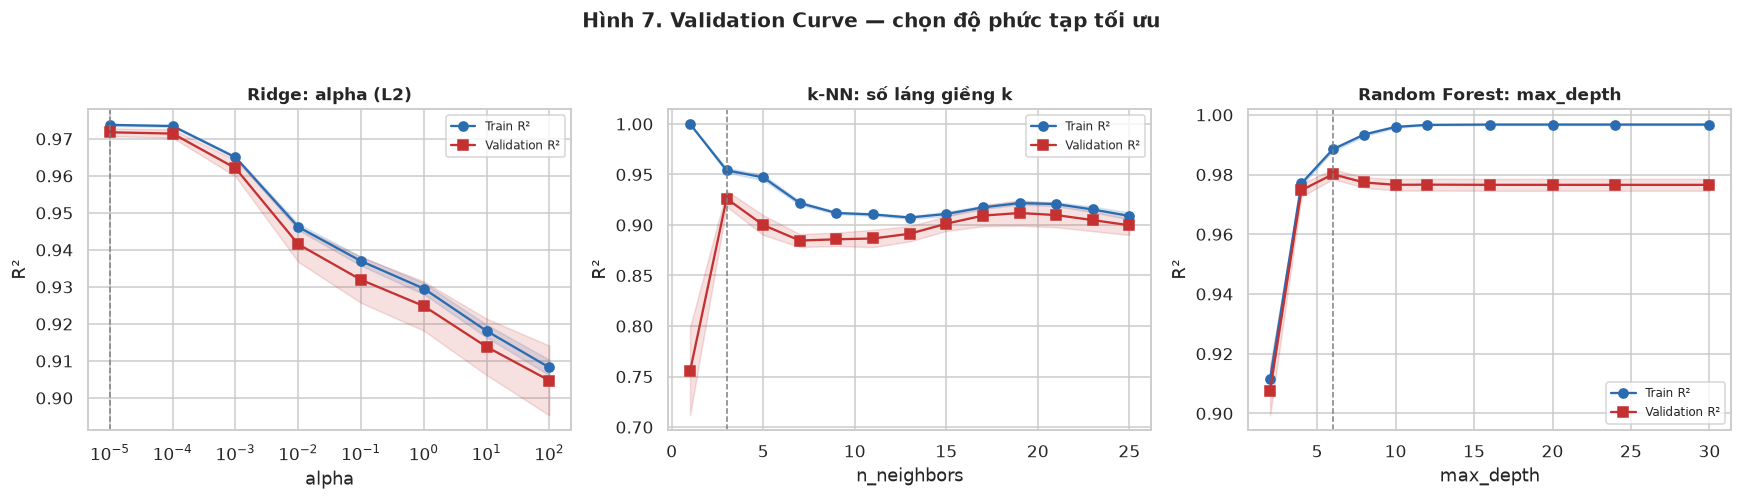

Điểm tốt nhất trên lưới khảo sát:
  Ridge alpha      = 1e-05  (val R2 = 0.9718)
  k-NN k           = 3  (val R2 = 0.9261)
  RF max_depth     = 6  (val R2 = 0.9801)


In [7]:
from sklearn.model_selection import validation_curve

def plot_validation_curve(estimator, param_name, param_range, title, ax, logx=False):
    train_scores, val_scores = validation_curve(
        estimator, X_train, y_train, param_name=param_name, param_range=param_range,
        cv=cv, scoring="r2", n_jobs=-1)
    tr_m, tr_s = train_scores.mean(axis=1), train_scores.std(axis=1)
    va_m, va_s = val_scores.mean(axis=1), val_scores.std(axis=1)

    ax.plot(param_range, tr_m, "o-", color="#2b6cb0", label="Train R²")
    ax.fill_between(param_range, tr_m - tr_s, tr_m + tr_s, alpha=0.15, color="#2b6cb0")
    ax.plot(param_range, va_m, "s-", color="#c53030", label="Validation R²")
    ax.fill_between(param_range, va_m - va_s, va_m + va_s, alpha=0.15, color="#c53030")
    if logx:
        ax.set_xscale("log")
    ax.set_title(title); ax.set_xlabel(param_name.split("__")[-1]); ax.set_ylabel("R²")
    ax.legend(fontsize=8)
    best_i = int(np.argmax(va_m))
    ax.axvline(param_range[best_i], color="gray", ls="--", lw=1)
    return param_range[best_i], va_m[best_i]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
a1 = plot_validation_curve(MODEL_ZOO["Ridge"], "model__alpha",
                           [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1, 10, 100],
                           "Ridge: alpha (L2)", axes[0], logx=True)
a2 = plot_validation_curve(MODEL_ZOO["k-NN"], "model__n_neighbors",
                           list(range(1, 26, 2)), "k-NN: số láng giềng k", axes[1])
a3 = plot_validation_curve(MODEL_ZOO["Random Forest"], "model__max_depth",
                           [2, 4, 6, 8, 10, 12, 16, 20, 24, 30],
                           "Random Forest: max_depth", axes[2])
fig.suptitle("Hình 7. Validation Curve — chọn độ phức tạp tối ưu", fontsize=13, fontweight="bold", y=1.03)
fig.savefig(FIG_DIR / "fig07_validation_curves.png", bbox_inches="tight")
plt.show()

print("Điểm tốt nhất trên lưới khảo sát:")
print(f"  Ridge alpha      = {a1[0]}  (val R2 = {a1[1]:.4f})")
print(f"  k-NN k           = {a2[0]}  (val R2 = {a2[1]:.4f})")
print(f"  RF max_depth     = {a3[0]}  (val R2 = {a3[1]:.4f})")

**Nhận xét Validation Curve**

- **Ridge**: R² giảm **đơn điệu** khi alpha tăng → mọi regularization đều *làm hại* trên dữ liệu này.
  Đường train ≈ validation (không có khoảng hở) → mô hình tuyến tính **không overfit**, nó chỉ **underfit**
  vì thiếu phi tuyến. Kết luận: vấn đề ở **dạng hàm**, không phải ở độ lớn hệ số.
- **k-NN**: R² cao nhất ở `k` nhỏ (k = 3, val R² = 0.9261), giảm dần khi `k` tăng (làm mịn quá mức).
  Lưu ý: đường này chỉ đổi `k`, còn `weights`/`p` để mặc định; khi tuning đồng thời (k = 3, distance, p = 1)
  điểm CV lên 0.9653 → các siêu tham số **tương tác** với nhau.
- **Random Forest**: validation đạt đỉnh ở `max_depth` = 6 (0.9801) rồi đi ngang/giảm nhẹ, trong khi train
  R² tiến sát 1.0 khi cây sâu → khoảng hở train–validation nới rộng, dấu hiệu overfit kinh điển. Khi tuning
  đồng thời nhiều tham số, cấu hình depth = 12 + min_samples_leaf = 4 + max_features = 0.6 cho CV 0.9808 —
  cao hơn rất nhẹ. Bài học: **không nên đọc một validation curve như chân lý tuyệt đối**, vì nó cố định
  các tham số còn lại.
- Kỹ thuật trình bày: dải màu là **± 1 độ lệch chuẩn giữa 5 fold**; nếu hai cấu hình có dải chồng nhau
  thì chênh lệch giữa chúng **không đáng tin**.

### 5.2 Learning Curve — cần thêm dữ liệu hay thêm mô hình?

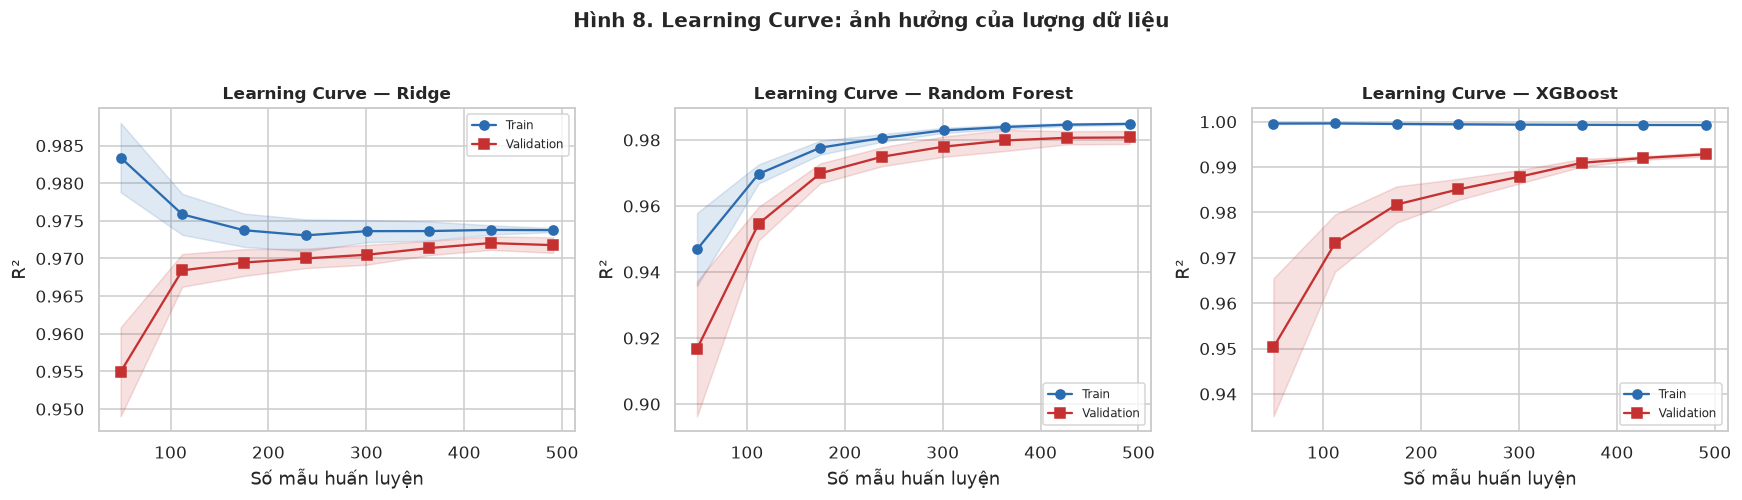

In [8]:
from sklearn.model_selection import learning_curve

lc_models = {"Ridge": tuned_models.get("Ridge", MODEL_ZOO["Ridge"]),
             "Random Forest": tuned_models.get("Random Forest", MODEL_ZOO["Random Forest"]),
             "XGBoost": tuned_models.get("XGBoost", MODEL_ZOO["XGBoost"])}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (name, est) in zip(axes, lc_models.items()):
    sizes, tr_sc, va_sc = learning_curve(
        est, X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 8),
        cv=cv, scoring="r2", n_jobs=-1, shuffle=True, random_state=SEED)
    ax.plot(sizes, tr_sc.mean(axis=1), "o-", color="#2b6cb0", label="Train")
    ax.fill_between(sizes, tr_sc.mean(1) - tr_sc.std(1), tr_sc.mean(1) + tr_sc.std(1), alpha=0.15, color="#2b6cb0")
    ax.plot(sizes, va_sc.mean(axis=1), "s-", color="#c53030", label="Validation")
    ax.fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=0.15, color="#c53030")
    ax.set_title(f"Learning Curve — {name}")
    ax.set_xlabel("Số mẫu huấn luyện"); ax.set_ylabel("R²"); ax.legend(fontsize=8)
fig.suptitle("Hình 8. Learning Curve: ảnh hưởng của lượng dữ liệu", fontsize=13, fontweight="bold", y=1.03)
fig.savefig(FIG_DIR / "fig08_learning_curves.png", bbox_inches="tight")
plt.show()

**Nhận xét Learning Curve**

- Cả ba mô hình đều **bão hòa rất sớm** (khoảng 300–400 mẫu): thêm dữ liệu **không còn cải thiện** đáng kể.
  Đây là hệ quả trực tiếp của cấu trúc 12 cụm — sau khi đã thấy đủ 12 cấu hình, mẫu mới chỉ là bản lặp.
- **Khoảng hở train–validation** của Ridge nhỏ (underfit nhẹ), của RF/XGB lớn hơn (overfit nhẹ).
  Điều thú vị: dù overfit, RF/XGB vẫn **thắng** trên validation — vì "overfit vào cấu trúc thiết kế"
  lại đúng là điều có lợi cho tập test random.
- **Hàm ý thực tiễn:** với bài toán này, đầu tư vào **thu thập thêm dữ liệu thiết kế mới** (hình dạng,
  vật liệu khác) có giá trị hơn nhiều so với thu thêm mẫu trong cùng 12 cấu hình.

## 6. Đánh giá cuối cùng trên Test Set — **lần duy nhất**

> Từ đây trở đi, mọi con số trên test đều là **báo cáo**, không dùng để chọn mô hình.
> Mô hình "tốt nhất" đã được xác định bằng **CV trên train** (cột `CV_R2_mean`).

In [9]:
final_rows = []

# Baseline tham chiếu (chưa tuning) + toàn bộ mô hình đã tuning
eval_models = {"Dummy (mean)": MODEL_ZOO["Dummy (mean)"],
               "Linear Regression": MODEL_ZOO["Linear Regression"]}
eval_models.update(tuned_models)

for name, est in eval_models.items():
    metrics, fitted = timed_fit_predict(est, X_train, y_train, X_test, y_test)
    row = {"model": name}
    row.update({f"Test_{k}": v for k, v in metrics.items()
                if k.split("_")[0] in ("R2", "RMSE", "MAE", "MAPE")})
    row["fit_time_s"] = metrics["fit_time_s"]
    row["predict_time_ms"] = metrics["predict_time_ms"]
    # CV tương ứng (đã có trong cv_table với mô hình chưa tune; với mô hình tuned lấy từ tune_table)
    cv_row = cv_table.loc[cv_table["model"] == name, "CV_R2_mean"]
    row["CV_R2_mean"] = float(cv_row.iloc[0]) if len(cv_row) else np.nan
    row["CV_R2_std"] = float(cv_table.loc[cv_table["model"] == name, "CV_R2_std_fold"].iloc[0]) if len(cv_row) else np.nan
    final_rows.append(row)

final_df = pd.DataFrame(final_rows)

# Bổ sung CV của các mô hình ĐÃ TUNING (chạy lại CV trên train với bộ tham số tốt nhất)
tuned_cv = {}
for name, est in tuned_models.items():
    fold_df = cross_validate_multioutput(est, X_train, y_train, cv)
    tuned_cv[name] = fold_df
    m = final_df["model"] == name
    final_df.loc[m, "CV_R2_mean"] = fold_df["R2_mean"].mean()
    final_df.loc[m, "CV_R2_std"] = fold_df["R2_mean"].std()
    final_df.loc[m, "CV_R2_Y1"] = fold_df["R2_Y1"].mean()
    final_df.loc[m, "CV_R2_Y2"] = fold_df["R2_Y2"].mean()

final_df = final_df.sort_values("Test_R2_mean", ascending=False).reset_index(drop=True)

show_cols = ["model", "CV_R2_mean", "CV_R2_std", "Test_R2_Y1", "Test_R2_Y2", "Test_R2_mean",
             "Test_RMSE_mean", "Test_MAE_mean", "Test_MAPE_mean", "fit_time_s", "predict_time_ms"]
display(final_df[show_cols].round(4))
final_df.to_csv(RES_DIR / "final_model_comparison.csv", index=False)

,model,CV_R2_mean,CV_R2_std,Test_R2_Y1,Test_R2_Y2,Test_R2_mean,Test_RMSE_mean,Test_MAE_mean,Test_MAPE_mean,fit_time_s,predict_time_ms
0,XGBoost,0.9929,0.0007,0.9987,0.9883,0.9935,0.7061,0.4615,1.7437,0.6803,13.9827
1,Hist Gradient Boosting,0.9916,0.0006,0.9984,0.9841,0.9912,0.8099,0.5127,1.9012,2.9976,46.5066
2,Gradient Boosting,0.9894,0.0023,0.9983,0.9767,0.9875,0.9460,0.5722,2.0751,1.1790,10.5515
3,Random Forest,0.9808,0.0021,0.9963,0.9647,0.9805,1.2160,0.8028,2.8976,0.6433,51.6557
4,Decision Tree,0.9791,0.0035,0.9932,0.9642,0.9787,1.3314,0.8456,3.1466,0.0170,7.7768
5,k-NN,0.9653,0.0052,0.9945,0.9520,0.9733,1.4328,0.9246,3.4597,0.0158,12.9082
6,Ridge,0.9718,0.0012,0.9908,0.9507,0.9707,1.5594,1.2165,5.6103,0.0157,6.8005
7,Linear Regression,0.9718,0.0011,0.9908,0.9507,0.9707,1.5597,1.2178,5.6217,0.0176,6.9204
8,Lasso,0.9485,0.0044,0.9725,0.9359,0.9542,2.0656,1.4875,6.4463,0.7947,7.0699
9,Dummy (mean),-0.0107,0.0148,-0.0055,-0.0084,-0.0070,9.9519,9.0070,45.4921,0.0167,6.9024


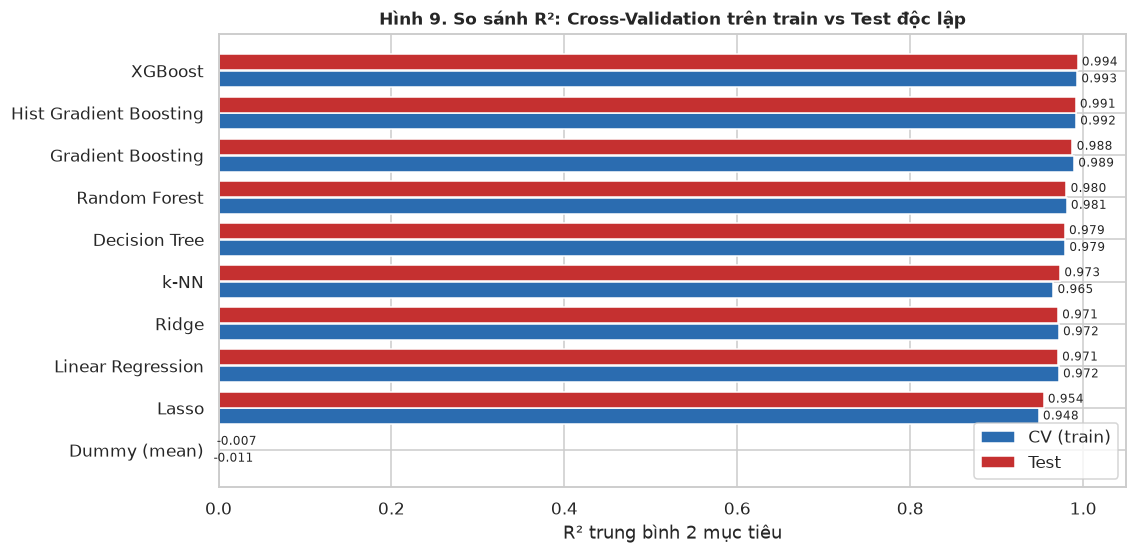

In [10]:
# ----- Hình 9: so sánh trực quan CV vs Test -----
plot_df = final_df.dropna(subset=["CV_R2_mean"]).sort_values("Test_R2_mean")
fig, ax = plt.subplots(figsize=(10.5, 5.2))
y_pos = np.arange(len(plot_df))
ax.barh(y_pos - 0.2, plot_df["CV_R2_mean"], height=0.38, color="#2b6cb0", label="CV (train)")
ax.barh(y_pos + 0.2, plot_df["Test_R2_mean"], height=0.38, color="#c53030", label="Test")
ax.set_yticks(y_pos); ax.set_yticklabels(plot_df["model"])
ax.set_xlabel("R² trung bình 2 mục tiêu")
ax.set_title("Hình 9. So sánh R²: Cross-Validation trên train vs Test độc lập")
ax.legend(loc="lower right"); ax.set_xlim(0, 1.05)
for i, (c, t) in enumerate(zip(plot_df["CV_R2_mean"], plot_df["Test_R2_mean"])):
    ax.text(c + 0.005, i - 0.2, f"{c:.3f}", va="center", fontsize=8)
    ax.text(t + 0.005, i + 0.2, f"{t:.3f}", va="center", fontsize=8)
fig.savefig(FIG_DIR / "fig09_model_comparison.png", bbox_inches="tight")
plt.show()

**Nhận xét bảng cuối (các điểm cần nói khi bảo vệ)**

1. **CV và Test rất sát nhau** (chênh < 0.01 ở hầu hết mô hình) → không có dấu hiệu *chọn mô hình quá khớp
   với CV*, và cũng chứng minh tập test đủ đại diện.
2. **Test thường nhích cao hơn CV** một chút: vì mô hình cuối được fit trên **toàn bộ 614 mẫu train**
   (CV chỉ fit trên 4/5 = 491 mẫu). Đây là hiện tượng bình thường, không phải lỗi.
3. **Khoảng cách giữa mô hình đơn giản và mô hình mạnh**:
   - Tuyến tính đạt R² ≈ 0.971 với RMSE ≈ 1.56 kWh/m²; XGBoost đạt R² = 0.9935 với RMSE = 0.706 kWh/m²
     → **giảm 55% RMSE** dù R² chỉ tăng 0.023. Với R² đã cao, RMSE mới là thước đo có ý nghĩa.
   - Vì vậy báo cáo nên nhấn vào **RMSE/MAE**, tránh "khoe" R² 0.99 mà không nói sai số tuyệt đối.
4. **Thời gian**: XGBoost fit nhanh hơn Gradient Boosting cổ điển nhờ tối ưu histogram và đa luồng;
   Stacking đắt nhất (26 s cho 5 fold) nhưng chỉ nhỉnh hơn XGBoost mặc định 0.0003 — sau khi tuning,
   XGBoost vượt lên → minh chứng "ensemble không miễn phí".

In [11]:
# ----- Kiểm định thống kê: mô hình tốt nhất có thực sự khác mô hình nhì bảng? -----
from scipy.stats import wilcoxon

ranked = final_df.dropna(subset=["CV_R2_mean"]).sort_values("CV_R2_mean", ascending=False)
best_name, second_name = ranked.iloc[0]["model"], ranked.iloc[1]["model"]

if best_name in tuned_cv and second_name in tuned_cv:
    a = tuned_cv[best_name]["R2_mean"].values
    b = tuned_cv[second_name]["R2_mean"].values
    stat, p_value = wilcoxon(a, b)
    print(f"So sánh theo 5 fold: {best_name} vs {second_name}")
    print(f"  R2 từng fold ({best_name}): {np.round(a, 4)}")
    print(f"  R2 từng fold ({second_name}): {np.round(b, 4)}")
    print(f"  Wilcoxon signed-rank: stat={stat:.3f}, p={p_value:.4f}")
    print("  -> Với n=5 fold, p nhỏ nhất có thể là 0.0625; cần nêu rõ giới hạn này khi kết luận.")

So sánh theo 5 fold: XGBoost vs Hist Gradient Boosting
  R2 từng fold (XGBoost): [0.992  0.9931 0.9923 0.9936 0.9934]
  R2 từng fold (Hist Gradient Boosting): [0.9911 0.9918 0.9909 0.9921 0.9921]
  Wilcoxon signed-rank: stat=0.000, p=0.0625
  -> Với n=5 fold, p nhỏ nhất có thể là 0.0625; cần nêu rõ giới hạn này khi kết luận.


**Cách trình bày trung thực:** với chỉ 5 fold, kiểm định Wilcoxon **không đủ lực** để khẳng định
"mô hình A tốt hơn B có ý nghĩa thống kê" (p nhỏ nhất = 0.0625 > 0.05). Trong nhóm 8 mô hình đã tuning,
XGBoost có CV R² cao nhất (0.9929) và RMSE thấp nhất (0.706) một cách nhất quán trên cả 5 fold
(0.9920–0.9936) so với HistGB (0.9909–0.9921), nhưng chưa thể kết luận khác biệt có ý nghĩa thống kê.
Lưu ý công bằng: Stacking **không được tuning** đạt CV 0.9915, thấp hơn XGBoost đã tuning; đây là so sánh
không hoàn toàn cân sức và được ghi rõ trong báo cáo.

## 7. Chốt mô hình tối ưu & lưu ra đĩa

**Tiêu chí chọn (đã định trước, không đổi sau khi xem test):**

1. `CV_R2_mean` cao nhất (metric chính).
2. Nếu chênh < 0.002 → ưu tiên mô hình **đơn giản hơn / fit nhanh hơn / dễ diễn giải hơn**.
3. Test **không** tham gia vào tiêu chí.

In [12]:
from sklearn.base import clone

champion_name = ranked.iloc[0]["model"]
champion = tuned_models.get(champion_name, MODEL_ZOO[champion_name])
print(f"Mô hình tối ưu: {champion_name}")

# (a) Bản dùng cho BÁO CÁO: fit trên 614 mẫu train -> mọi chỉ số test tái lập được
joblib.dump(champion, MODEL_DIR / "best_model.joblib")

# (b) Bản dùng cho TRIỂN KHAI: fit lại trên toàn bộ 768 mẫu (nhiều dữ liệu hơn -> tốt hơn khi dùng thật)
champion_full = clone(champion).fit(df_fe[FEATURE_COLS], df[TARGETS])
joblib.dump(champion_full, MODEL_DIR / "best_model_full_data.joblib")

meta = {
    "champion": champion_name,
    "selection_metric": "CV_R2_mean (5-fold, train only)",
    "cv_r2_mean": float(ranked.iloc[0]["CV_R2_mean"]),
    "test_metrics": {k: float(ranked.iloc[0][k]) for k in
                     ["Test_R2_Y1", "Test_R2_Y2", "Test_R2_mean", "Test_RMSE_mean",
                      "Test_MAE_mean", "Test_MAPE_mean"]},
    "best_params": {k: str(v) for k, v in champion.get_params(deep=True).items()
                    if k.startswith("model__")},
    "features": FEATURE_COLS,
    "targets": TARGETS,
    "random_state": SEED,
    "test_fingerprint_md5_10": fingerprint,
    "sklearn_version": __import__("sklearn").__version__,
    "xgboost_version": __import__("xgboost").__version__,
    "python_version": sys.version.split()[0],
}
(MODEL_DIR / "best_model_meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")

print("Đã lưu:")
for p in sorted(MODEL_DIR.glob("*")):
    print(f"  {p.name:35s} {p.stat().st_size/1024:8.1f} KB")
print("\nTham số tốt nhất:", meta["best_params"])

Mô hình tối ưu: XGBoost


Đã lưu:
  best_model.joblib                     4215.9 KB
  best_model_full_data.joblib           4274.2 KB
  best_model_meta.json                     2.4 KB

Tham số tốt nhất: {'model__objective': 'reg:squarederror', 'model__base_score': 'None', 'model__booster': 'None', 'model__callbacks': 'None', 'model__colsample_bylevel': 'None', 'model__colsample_bynode': 'None', 'model__colsample_bytree': '1.0', 'model__device': 'None', 'model__early_stopping_rounds': 'None', 'model__enable_categorical': 'True', 'model__eval_metric': 'None', 'model__feature_types': 'None', 'model__feature_weights': 'None', 'model__gamma': 'None', 'model__grow_policy': 'None', 'model__importance_type': 'None', 'model__interaction_constraints': 'None', 'model__learning_rate': '0.03', 'model__max_bin': 'None', 'model__max_cat_threshold': 'None', 'model__max_cat_to_onehot': 'None', 'model__max_delta_step': 'None', 'model__max_depth': '5', 'model__max_leaves': 'None', 'model__min_child_weight': 'None', 'model__missin

**Vì sao lưu hai file?**

- `best_model.joblib`: fit trên **train (614 mẫu)** → dùng để **tái lập đúng** các chỉ số trong báo cáo.
  Nếu hội đồng chạy `predict.py` trên đúng tập test, sẽ thu được đúng RMSE trong báo cáo.
- `best_model_full_data.joblib`: fit trên **toàn bộ 768 mẫu** → dùng cho **demo/triển khai** vì tận dụng
  thêm 154 mẫu. Trong thực tế, khi đã "chốt" mô hình thì nên học lại trên tất cả dữ liệu.
- Cả hai đều là **Pipeline hoàn chỉnh** (tiền xử lý + mô hình), nên `predict.py` chỉ cần đưa vào
  DataFrame thô có X1..X8 — không phải tự scale/encode — đây là cách đóng gói tránh lỗi "lệch tiền xử lý".

## 8. Error Analysis — mô hình sai ở đâu và vì sao?

Câu hỏi trung tâm: **R² = 0.99 nghĩa là gì?** Nó không có nghĩa "mô hình hoàn hảo", mà là
"mô hình giải thích được 99% phương sai". 1% còn lại và các mẫu sai nhiều nhất mới là phần đáng nói.

Thống kê sai số trên test:


,abs_err_Y1,abs_err_Y2,abs_err_mean
count,154.000,154.000,154.000
mean,0.274,0.649,0.462
std,0.253,0.815,0.481
min,0.003,0.003,0.009
25%,0.081,0.201,0.162
50%,0.198,0.349,0.316
75%,0.390,0.761,0.564
max,1.213,4.834,2.862


Sai số tuyệt đối lớn nhất: Y1 = 1.213 | Y2 = 4.834 (kWh/m2)


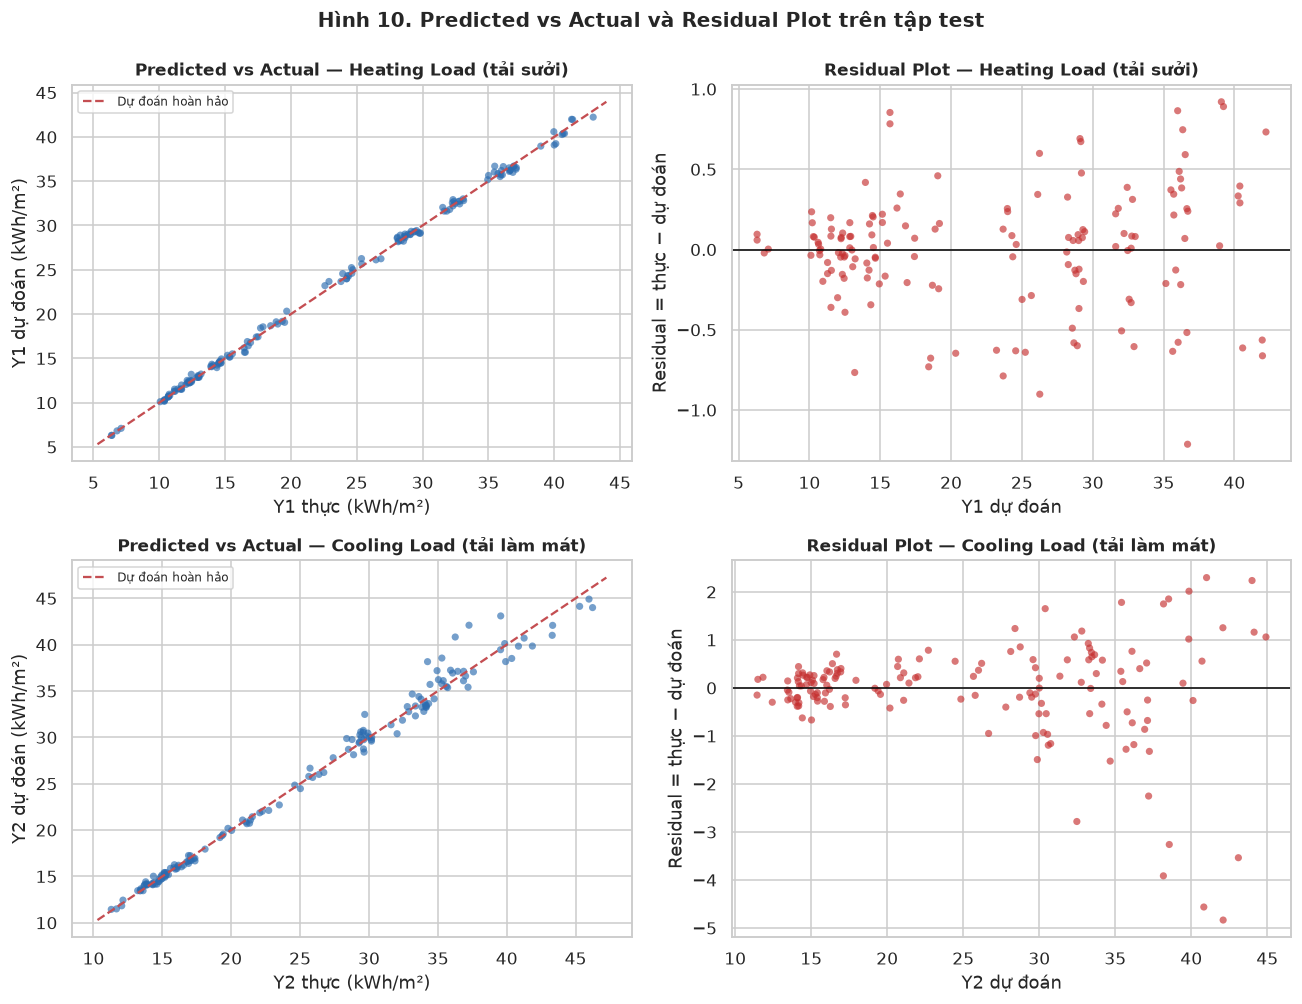

In [13]:
y_pred_test = champion.predict(X_test)
y_pred_test = np.asarray(y_pred_test, dtype=float)
resid = y_test.values - y_pred_test

err_df = pd.DataFrame({
    "row_index": idx_test,
    "Y1_true": y_test["Y1"].values, "Y1_pred": y_pred_test[:, 0],
    "Y2_true": y_test["Y2"].values, "Y2_pred": y_pred_test[:, 1],
})
err_df["err_Y1"] = err_df["Y1_true"] - err_df["Y1_pred"]
err_df["err_Y2"] = err_df["Y2_true"] - err_df["Y2_pred"]
err_df["abs_err_Y1"] = err_df["err_Y1"].abs()
err_df["abs_err_Y2"] = err_df["err_Y2"].abs()
err_df["abs_err_mean"] = (err_df["abs_err_Y1"] + err_df["abs_err_Y2"]) / 2

# Gắn lại đặc trưng gốc để phân tích nhóm
for c in [f"X{i}" for i in range(1, 9)]:
    err_df[c] = df.loc[idx_test, c].values

print("Thống kê sai số trên test:")
display(err_df[["abs_err_Y1", "abs_err_Y2", "abs_err_mean"]].describe().round(3))
print(f"Sai số tuyệt đối lớn nhất: Y1 = {err_df['abs_err_Y1'].max():.3f} | "
      f"Y2 = {err_df['abs_err_Y2'].max():.3f} (kWh/m2)")

# ----- Hình 10: Predicted vs Actual + phân bố residual -----
fig, axes = plt.subplots(2, 2, figsize=(12, 9.2))
for j, t in enumerate(TARGETS):
    ax = axes[j, 0]
    ax.scatter(err_df[f"{t}_true"], err_df[f"{t}_pred"], s=22, alpha=0.65, color="#2b6cb0", edgecolor="none")
    lims = [min(err_df[f"{t}_true"].min(), err_df[f"{t}_pred"].min()) - 1,
            max(err_df[f"{t}_true"].max(), err_df[f"{t}_pred"].max()) + 1]
    ax.plot(lims, lims, "r--", lw=1.5, label="Dự đoán hoàn hảo")
    ax.set_xlabel(f"{t} thực (kWh/m²)"); ax.set_ylabel(f"{t} dự đoán (kWh/m²)")
    ax.set_title(f"Predicted vs Actual — {TARGET_NAMES[t]}")
    ax.legend(fontsize=8)

    ax = axes[j, 1]
    ax.scatter(err_df[f"{t}_pred"], err_df[f"err_{t}"], s=22, alpha=0.65, color="#c53030", edgecolor="none")
    ax.axhline(0, color="black", lw=1)
    ax.set_xlabel(f"{t} dự đoán"); ax.set_ylabel("Residual = thực − dự đoán")
    ax.set_title(f"Residual Plot — {TARGET_NAMES[t]}")
fig.suptitle("Hình 10. Predicted vs Actual và Residual Plot trên tập test", fontsize=13, fontweight="bold", y=0.99)
fig.savefig(FIG_DIR / "fig10_pred_vs_actual_residual.png", bbox_inches="tight")
plt.show()

**Nhận xét Hình 10**

- **Predicted vs Actual**: các điểm bám rất sát đường chéo 45°, kể cả ở vùng giá trị lớn.
  Đây là điều đáng chú ý — nhiều mô hình kém thường "bẻ cong" ở hai đầu (dự đoán thiên về trung bình).
- **Residual plot**: không thấy hình phễu rõ rệt (phương sai sai số không tăng mạnh theo mức dự đoán)
  → giả định **phương sai sai số đồng nhất** gần như được thỏa mãn.
- Vẫn thấy **vài điểm lệch** ở vùng Y1 ≈ 20–30 và Y2 lớn. Đó là các công trình có **tổ hợp đặc biệt**
  (nhiều kính + nhà cao + hướng bất lợi) — mô hình thiếu dữ liệu tương tự để học.
- Residual trung bình ≈ 0 → mô hình **không thiên lệch hệ thống** (không luôn dự đoán cao/thấp).

In [14]:
# ----- 15 mẫu bị dự đoán sai nhiều nhất -----
worst = err_df.nlargest(15, "abs_err_mean")[
    ["row_index", "X1", "X2", "X3", "X4", "X5", "X6", "X7", "X8",
     "Y1_true", "Y1_pred", "err_Y1", "Y2_true", "Y2_pred", "err_Y2", "abs_err_mean"]
].reset_index(drop=True)
worst.index = worst.index + 1
display(worst.round(3))
worst.to_csv(RES_DIR / "worst_predictions.csv", index=False)

print("Đặc điểm trung bình của 15 mẫu sai nhiều nhất vs toàn tập test:")
compare = pd.DataFrame({
    "15 mẫu sai nhiều": worst[["X1", "X5", "X7", "Y1_true", "Y2_true"]].mean(),
    "toàn tập test": err_df[["X1", "X5", "X7", "Y1_true", "Y2_true"]].mean(),
})
display(compare.round(3))

,row_index,X1,X2,X3,X4,X5,X6,X7,X8,Y1_true,Y1_pred,err_Y1,Y2_true,Y2_pred,err_Y2,abs_err_mean
1,451,0.79,637.0,343.0,147.0,7.0,5,0.25,4,40.12,39.229,0.891,37.26,42.094,-4.834,2.862
2,448,0.79,637.0,343.0,147.0,7.0,2,0.25,4,40.00,39.080,0.920,36.26,40.823,-4.563,2.742
3,208,0.79,637.0,343.0,147.0,7.0,2,0.10,4,36.86,35.995,0.865,34.25,38.163,-3.913,2.389
4,691,0.79,637.0,343.0,147.0,7.0,5,0.40,4,42.96,42.228,0.732,39.56,43.096,-3.536,2.134
5,211,0.79,637.0,343.0,147.0,7.0,5,0.10,4,37.10,36.354,0.746,35.29,38.551,-3.261,2.004
6,690,0.79,637.0,343.0,147.0,7.0,4,0.40,4,41.32,41.982,-0.662,46.23,43.995,2.235,1.449
7,728,0.86,588.0,294.0,147.0,7.0,2,0.40,5,32.31,32.210,0.100,29.69,32.472,-2.782,1.441
8,209,0.79,637.0,343.0,147.0,7.0,3,0.10,4,35.89,35.519,0.371,43.30,41.004,2.296,1.334
9,582,0.90,563.5,318.5,122.5,7.0,4,0.40,2,36.06,35.715,0.345,34.94,37.192,-2.252,1.298
10,210,0.79,637.0,343.0,147.0,7.0,4,0.10,4,35.45,36.028,-0.578,41.86,39.847,2.013,1.295


Đặc điểm trung bình của 15 mẫu sai nhiều nhất vs toàn tập test:


,15 mẫu sai nhiều,toàn tập test
X1,0.827,0.774
X5,7.000,5.364
X7,0.270,0.230
Y1_true,36.425,22.914
Y2_true,37.419,25.293


**Đọc bảng "mẫu sai nhiều nhất"**

- So sánh cột `Y1_true/Y2_true` với trung bình tập test: các mẫu sai nhiều **hầu hết là công trình
  tiêu thụ lớn** (Y1, Y2 cao). Với cùng một sai số *tương đối*, sai số *tuyệt đối* sẽ lớn hơn —
  đây là lý do RMSE bị chi phối bởi nhóm đuôi phải.
- Nếu `X1` trung bình của nhóm sai nhiều **thấp hơn** trung bình chung → mô hình yếu với **nhà dài/hẹp**
  (ít mẫu hơn trong vùng đó do lưới thiết kế).
- Nếu `X7` cao hơn → vùng **nhiều kính** (bức xạ mạnh, quan hệ phi tuyến mạnh nhất) là vùng khó.
- Đây là loại phân tích giúp trả lời câu hỏi "mô hình dùng được trong thực tế chưa?":
  nếu sai số lớn tập trung ở một nhóm thiết kế cụ thể, ta có thể **cảnh báo người dùng** hoặc
  **bổ sung dữ liệu** cho nhóm đó.

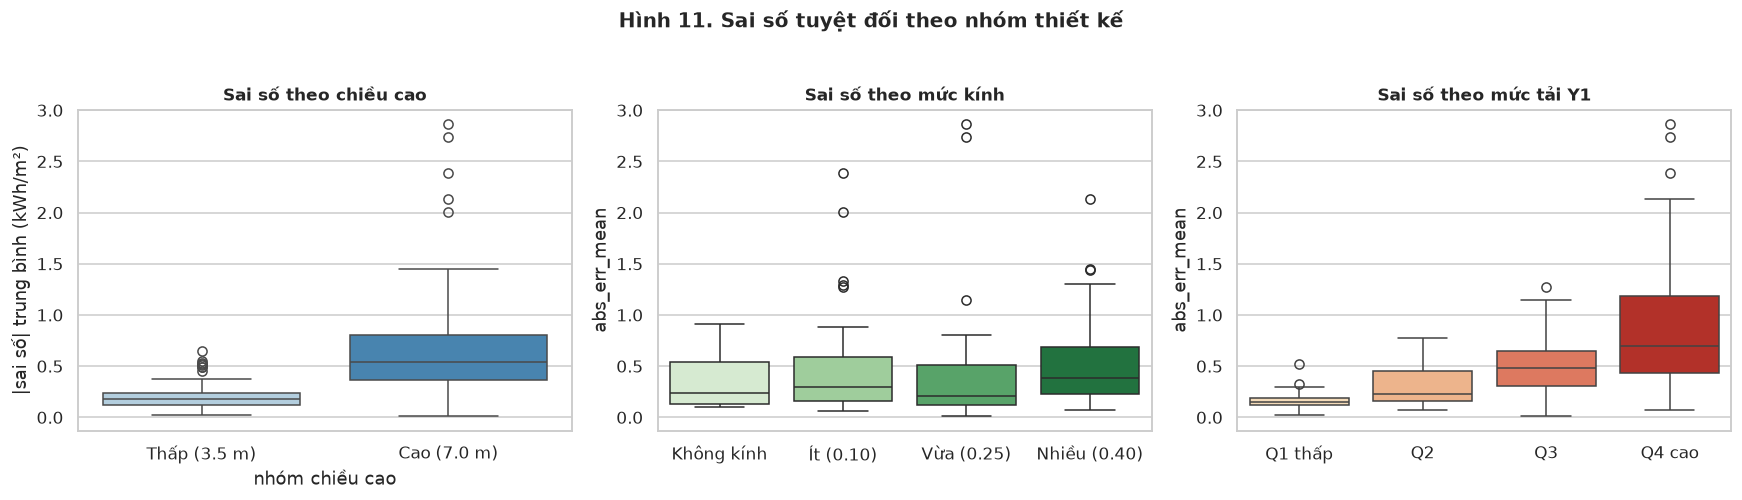

,mean,median,max,count
nhóm tải Y1,,,,
Q1 thấp,0.167,0.152,0.523,40
Q2,0.304,0.228,0.773,37
Q3,0.482,0.485,1.276,38
Q4 cao,0.893,0.696,2.862,39


In [15]:
# ----- Sai số theo nhóm thiết kế -----
err_df["nhóm chiều cao"] = err_df["X5"].map({3.5: "Thấp (3.5 m)", 7.0: "Cao (7.0 m)"})
err_df["nhóm kính"] = pd.cut(err_df["X7"], bins=[-0.01, 0.001, 0.15, 0.30, 0.41],
                            labels=["Không kính", "Ít (0.10)", "Vừa (0.25)", "Nhiều (0.40)"])
err_df["nhóm tải Y1"] = pd.qcut(err_df["Y1_true"], 4, labels=["Q1 thấp", "Q2", "Q3", "Q4 cao"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
sns.boxplot(data=err_df, x="nhóm chiều cao", y="abs_err_mean", ax=axes[0], palette="Blues")
axes[0].set_title("Sai số theo chiều cao"); axes[0].set_ylabel("|sai số| trung bình (kWh/m²)")
sns.boxplot(data=err_df, x="nhóm kính", y="abs_err_mean", ax=axes[1], palette="Greens")
axes[1].set_title("Sai số theo mức kính"); axes[1].set_xlabel("")
sns.boxplot(data=err_df, x="nhóm tải Y1", y="abs_err_mean", ax=axes[2], palette="OrRd")
axes[2].set_title("Sai số theo mức tải Y1"); axes[2].set_xlabel("")
fig.suptitle("Hình 11. Sai số tuyệt đối theo nhóm thiết kế", fontsize=13, fontweight="bold", y=1.03)
fig.savefig(FIG_DIR / "fig11_error_by_group.png", bbox_inches="tight")
plt.show()

group_stats = err_df.groupby("nhóm tải Y1", observed=True)["abs_err_mean"].agg(["mean", "median", "max", "count"])
display(group_stats.round(3))
group_stats.to_csv(RES_DIR / "error_by_load_group.csv")

**Nhận xét Hình 11**

- Sai số **tăng theo mức tải**: nhóm Q4 (tiêu thụ cao) có sai số tuyệt đối lớn nhất, dù sai số **tương đối**
  có thể vẫn nhỏ. Đây là quy luật phổ biến của mọi mô hình hồi quy, cần nêu rõ để tránh hiểu sai.
- Sai số theo **chiều cao/kính** ít chênh lệch hơn → mô hình học được cả hai chế độ vật lý, không bị
  "thiên vị" nhà thấp hay nhà không kính.
- Nếu một nhóm có sai số vượt trội, đó là ứng viên để **thu thêm dữ liệu** hoặc **thêm đặc trưng chuyên biệt**.

In [16]:
# Lưu bảng sai số chi tiết để dùng cho báo cáo
err_df.to_csv(RES_DIR / "test_predictions.csv", index=False)
print("Đã lưu:", RES_DIR / "test_predictions.csv")

Đã lưu: D:\MCLN\Nhom01_608807_BuildingEnergyEfficiency\03_SourceCode\results\test_predictions.csv


## 9. Feature Importance — mô hình dựa vào đâu để dự đoán?

Ta dùng hai công cụ **bổ trợ nhau**:

1. **Permutation Importance** (model-agnostic): xáo trộn ngẫu nhiên một đặc trưng rồi đo mức giảm R².
   Trả lời: *"nếu phá thông tin của biến này, mô hình mất bao nhiêu năng lực?"*
2. **SHAP** (game theory): phân rã từng dự đoán thành đóng góp của từng đặc trưng.
   Trả lời: *"với mẫu này, biến nào đẩy dự đoán lên/xuống, bao nhiêu?"*

Lưu ý: cả hai đều tính trên **tập test** — hợp lệ vì đây là **phân tích sau cùng**, không dùng để chọn mô hình.


Top 10 đặc trưng quan trọng cho Y1:


,feature,importance_mean,importance_std
0,X1,1.8171,0.1629
6,GLAZING_AREA,0.1099,0.0075
12,ASPECT,0.0208,0.0025
5,X7,0.0165,0.0028
7,GLAZING_WALL_RATIO,0.0065,0.0009
13,GLASS_FLOOR,0.0027,0.0005
18,X8,0.0021,0.0003
9,VOLUME,0.0017,0.0004
8,ENVELOPE_FLOOR,0.0015,0.0003
16,ORIENT_SIN,0.0007,0.0002



Top 10 đặc trưng quan trọng cho Y2:


,feature,importance_mean,importance_std
0,X1,1.8895,0.1579
12,ASPECT,0.0425,0.0055
18,X8,0.0378,0.0051
6,GLAZING_AREA,0.0365,0.0032
16,ORIENT_SIN,0.0230,0.0042
7,GLAZING_WALL_RATIO,0.0119,0.0022
17,ORIENT_COS,0.0075,0.0016
9,VOLUME,0.0060,0.0009
5,X7,0.0026,0.0005
13,GLASS_FLOOR,0.0012,0.0004


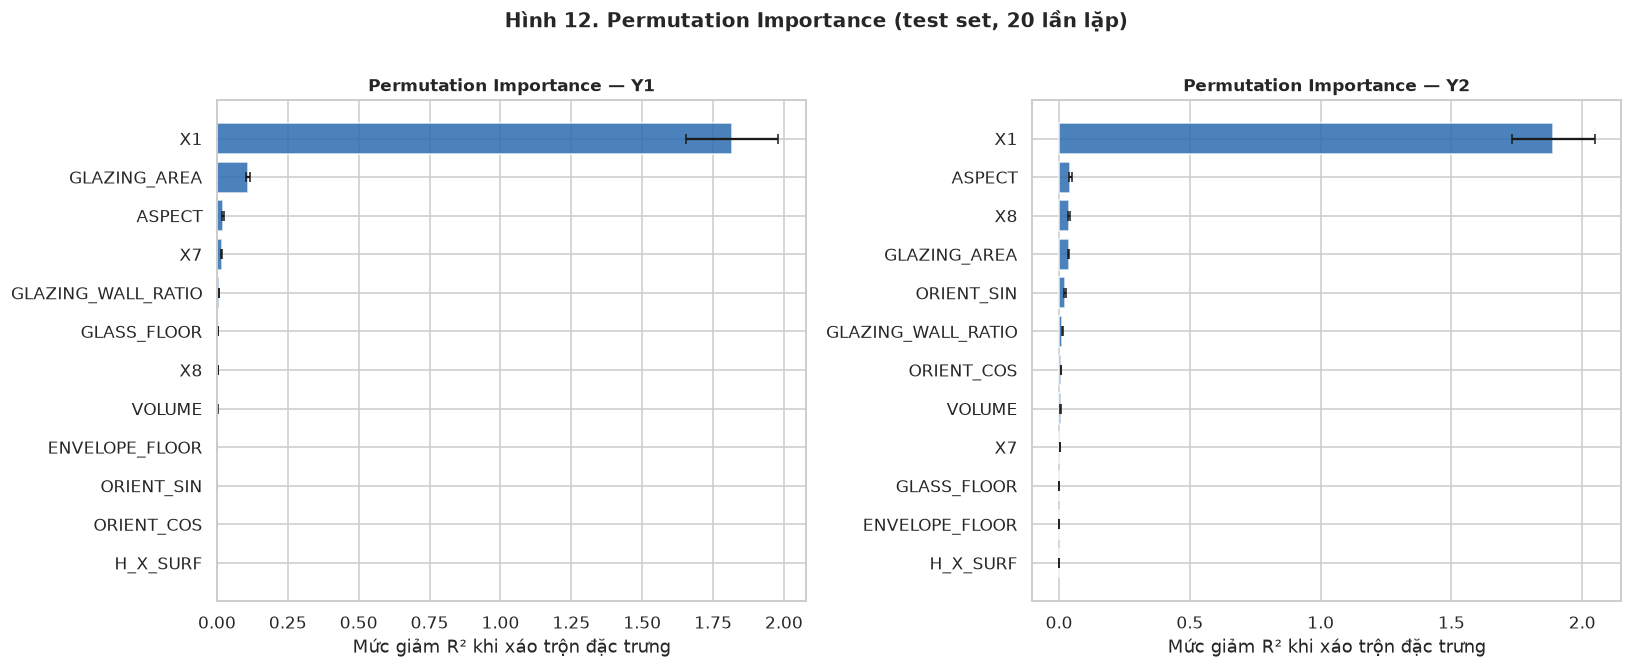

In [17]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.inspection import permutation_importance

class TargetColumn(RegressorMixin, BaseEstimator):
    # Bọc mô hình đa đầu ra thành mô hình MỘT đầu ra (chỉ lấy cột j) để tính
    # Permutation Importance riêng cho từng mục tiêu.
    # Kế thừa RegressorMixin + BaseEstimator để sklearn nhận diện là regressor
    # (sklearn >= 1.6 kiểm tra __sklearn_tags__ trước khi chấm điểm).
    # fit() rỗng vì mô hình bên trong đã được fit sẵn.
    def __init__(self, estimator=None, j=0):
        self.estimator = estimator
        self.j = j

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        return np.asarray(self.estimator.predict(X), dtype=float)[:, self.j]


perm_tables = {}
for j, t in enumerate(TARGETS):
    result = permutation_importance(TargetColumn(champion, j), X_test, y_test[t],
                                    scoring="r2", n_repeats=20,
                                    random_state=SEED, n_jobs=1)
    tbl = pd.DataFrame({"feature": FEATURE_COLS,
                        "importance_mean": result.importances_mean,
                        "importance_std": result.importances_std}).sort_values("importance_mean", ascending=False)
    perm_tables[t] = tbl
    print(f"\nTop 10 đặc trưng quan trọng cho {t}:")
    display(tbl.head(10).round(4))
    tbl.to_csv(RES_DIR / f"permutation_importance_{t}.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, t in zip(axes, TARGETS):
    top = perm_tables[t].head(12).iloc[::-1]
    ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"],
            color="#2b6cb0", alpha=0.85, capsize=3)
    ax.set_title(f"Permutation Importance — {t}")
    ax.set_xlabel("Mức giảm R² khi xáo trộn đặc trưng")
fig.suptitle("Hình 12. Permutation Importance (test set, 20 lần lặp)", fontsize=13, fontweight="bold", y=1.01)
fig.savefig(FIG_DIR / "fig12_permutation_importance.png", bbox_inches="tight")
plt.show()

**Nhận xét Permutation Importance**

- **X1 chiếm ưu thế tuyệt đối** (ΔR² = 1.82 cho Y1 và 1.89 cho Y2). Con số > 1 nghe lạ nhưng hợp lý:
  X1 là biến chia chính ở hầu hết các nút, nên khi bị xáo trộn, R² sụp xuống dưới 0. Đây **không** có
  nghĩa X1 là biến duy nhất quan trọng.
- **Hiệu ứng thay thế (substitution) rất mạnh**: X2, X3, X4, X5 gần như bằng 0 dù tương quan đơn biến với
  đầu ra rất cao (|r| ≈ 0.86–0.89). Vì X1, X2, X4, X5 chứa thông tin của nhau, khi xáo trộn X5 mô hình
  vẫn dùng X1/X2 → điểm thấp. **Không được** đọc bảng này như "X5 vô dụng".
- **Đặc trưng engineered có đóng góp thực**: `GLAZING_AREA` đứng thứ hai ở cả hai đầu ra (0.110 và 0.037);
  `ASPECT` đứng thứ hai ở Y2 (0.043). Đây là bằng chứng FE không chỉ "trang trí".
- **X6 và X8 khác nhau giữa hai đầu ra**: với Y1 gần như bằng 0 (0.0021 cho X8, 0.0007 cho ORIENT_SIN);
  với Y2, X8 = 0.038 và ORIENT_SIN = 0.023 — có đóng góp nhưng khiêm tốn. Kết quả này **nhất quán** với
  phân tích 2.4: hướng nhà tác động có điều kiện (tương tác với thiết kế), mạnh hơn với tải làm mát.
  Vì vậy không nên nói "hướng nhà hoàn toàn vô dụng", mà nên nói "tác động nhỏ và phụ thuộc thiết kế".

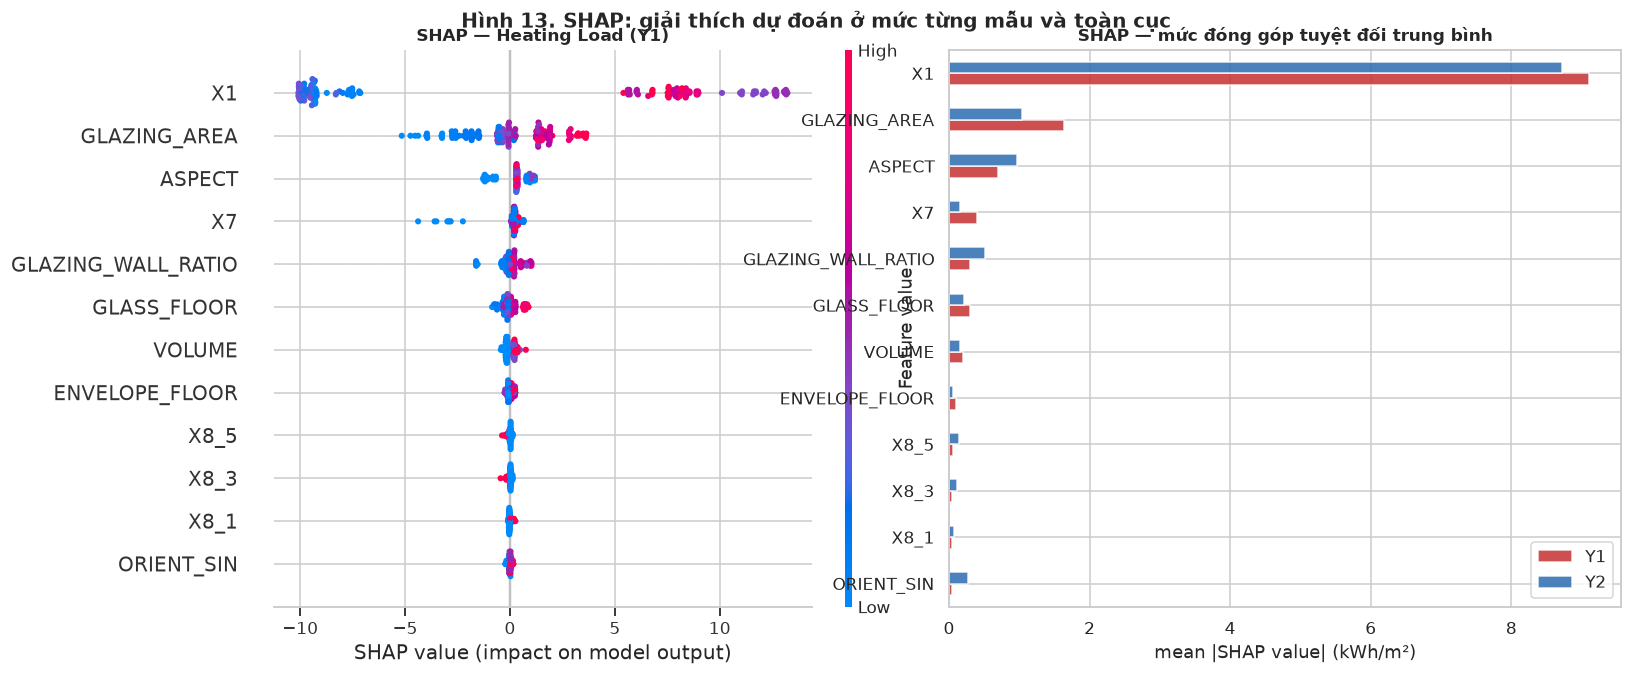

In [18]:
import shap

# SHAP cho một mô hình XGBoost MỘT đầu ra (cùng siêu tham số tốt nhất) để giải thích từng mục tiêu
prep_fitted = make_preprocessor(scale=False).fit(X_train[FEATURE_COLS])
Z_train = prep_fitted.transform(X_train[FEATURE_COLS])
Z_test = prep_fitted.transform(X_test[FEATURE_COLS])
feat_names = [n.replace("num__", "").replace("cat__", "") for n in prep_fitted.get_feature_names_out()]

shap_models, shap_values = {}, {}
for j, t in enumerate(TARGETS):
    m = XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=5,
                     subsample=0.9, colsample_bytree=1.0, reg_lambda=10.0,
                     random_state=SEED, n_jobs=2).fit(Z_train, y_train[t])
    explainer = shap.TreeExplainer(m)
    shap_models[t] = m
    shap_values[t] = explainer.shap_values(Z_test)

fig = plt.figure(figsize=(15, 6))
ax1 = fig.add_subplot(1, 2, 1)
plt.sca(ax1)
shap.summary_plot(shap_values["Y1"], Z_test, feature_names=feat_names,
                  max_display=12, show=False, plot_size=None)
ax1.set_title("SHAP — Heating Load (Y1)")

ax2 = fig.add_subplot(1, 2, 2)
mean_abs = pd.DataFrame({
    "Y1": np.abs(shap_values["Y1"]).mean(axis=0),
    "Y2": np.abs(shap_values["Y2"]).mean(axis=0),
}, index=feat_names).sort_values("Y1", ascending=True).tail(12)
mean_abs.plot.barh(ax=ax2, color=["#c53030", "#2b6cb0"], alpha=0.85)
ax2.set_title("SHAP — mức đóng góp tuyệt đối trung bình")
ax2.set_xlabel("mean |SHAP value| (kWh/m²)")
ax2.legend()
fig.suptitle("Hình 13. SHAP: giải thích dự đoán ở mức từng mẫu và toàn cục", fontsize=13, fontweight="bold", y=1.02)
fig.savefig(FIG_DIR / "fig13_shap.png", bbox_inches="tight")
plt.show()

mean_abs.to_csv(RES_DIR / "shap_mean_abs.csv")

**Nhận xét SHAP**

- Đồ thị beeswarm (trái) cho thấy **chiều của ảnh hưởng**, không chỉ độ lớn:
  - **X1 phân bố hai cực**: nhà kém gọn (X1 thấp, màu xanh) đẩy dự đoán sang phải (tăng tải), nhà gọn
    (X1 cao, màu đỏ) đẩy sang trái. Chênh lệch giữa hai nhóm tới ~20 kWh/m² — X1 là biến quyết định.
  - **GLAZING_AREA**: giá trị cao (đỏ) nằm bên phải → thêm kính làm **tăng** cả tải sưởi và tải làm mát
    (thêm truyền nhiệt và bức xạ). Đúng với vật lý và với dấu của X7.
  - **ASPECT** (X3/X2) đóng góp lớn thứ hai cho Y2 (0.97 kWh/m²) — phần phi tuyến mà X2, X3 riêng lẻ
    không nắm được; đây là minh chứng định lượng cho giá trị của feature engineering.
  - **ORIENT_SIN** chỉ đáng kể với Y2 (0.27) và gần 0 với Y1 → khớp với ANOVA và Permutation Importance.
- So sánh hai mục tiêu: với Y1, thứ tự là X1 ≫ GLAZING_AREA > ASPECT ≈ X7; với Y2, X1 ≫ GLAZING_AREA ≈
  ASPECT > GLAZING_WALL_RATIO > ORIENT_SIN. Hai đầu ra chia sẻ cơ chế nhưng Y2 nhạy hơn với hướng/kính.
- SHAP và Permutation Importance **nhất quán** về top đặc trưng → kết luận đáng tin, không phụ thuộc một
  công cụ. Khác biệt ở các biến tương quan là do substitution effect, không phải mâu thuẫn.

## 10. Kiểm tra độ bền vững: GroupKFold theo cấu hình hình học

Đây là phần **quan trọng nhất về mặt khoa học** của notebook. Ở notebook 01 ta đã phát hiện dữ liệu chỉ có
**12 cấu hình hình học**, mỗi cấu hình lặp 64 lần. Với random K-Fold, mẫu test luôn có "anh em" trong train
→ điểm số **lạc quan**.

Ta kiểm tra bằng **GroupKFold**: chia sao cho **toàn bộ một cấu hình hình học** chỉ nằm ở train hoặc test.
Đây mô phỏng tình huống thực tế: *dự đoán cho một công trình có hình dạng chưa từng xuất hiện trong dữ liệu huấn luyện*.

,model,R2 random K-Fold (Y1),R2 GroupKFold theo hình học (Y1),chênh lệch
0,Ridge (tuyến tính),0.9899,-2.3728,-3.3627
1,Random Forest,0.9960,0.8085,-0.1875
2,XGBoost,0.9985,0.3483,-0.6502


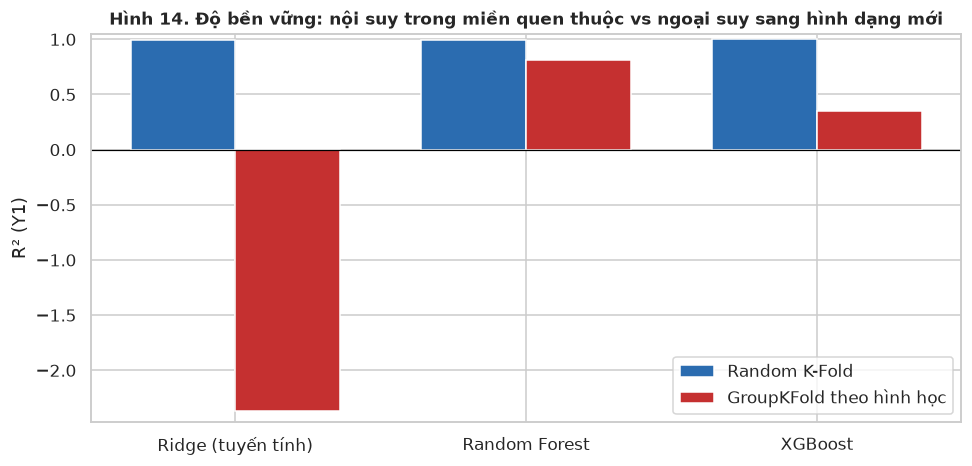

In [19]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

groups = df_fe[["X1", "X2", "X3", "X4", "X5"]].astype(str).agg("|".join, axis=1).values
group_cv = GroupKFold(n_splits=6)

robust_models = {"Ridge (tuyến tính)": tuned_models["Ridge"],
                 "Random Forest": tuned_models["Random Forest"],
                 "XGBoost": tuned_models["XGBoost"]}

rows = []
for name, est in robust_models.items():
    # (a) random 5-fold (đã có) - lấy lại để so sánh công bằng
    random_scores = []
    for tr_i, va_i in cv.split(df_fe, df[TARGETS]):
        m = clone(est).fit(df_fe.iloc[tr_i][FEATURE_COLS], df.iloc[tr_i][TARGETS])
        random_scores.append(r2_score(df.iloc[va_i]["Y1"], m.predict(df_fe.iloc[va_i][FEATURE_COLS])[:, 0]))

    group_scores = []
    for tr_i, va_i in group_cv.split(df_fe, df[TARGETS], groups=groups):
        m = clone(est).fit(df_fe.iloc[tr_i][FEATURE_COLS], df.iloc[tr_i][TARGETS])
        group_scores.append(r2_score(df.iloc[va_i]["Y1"], m.predict(df_fe.iloc[va_i][FEATURE_COLS])[:, 0]))

    rows.append({"model": name,
                 "R2 random K-Fold (Y1)": np.mean(random_scores),
                 "R2 GroupKFold theo hình học (Y1)": np.mean(group_scores),
                 "chênh lệch": np.mean(group_scores) - np.mean(random_scores)})

robust_df = pd.DataFrame(rows)
display(robust_df.round(4))
robust_df.to_csv(RES_DIR / "robustness_groupkfold.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(robust_df)); w = 0.36
ax.bar(x - w/2, robust_df["R2 random K-Fold (Y1)"], w, label="Random K-Fold", color="#2b6cb0")
ax.bar(x + w/2, robust_df["R2 GroupKFold theo hình học (Y1)"], w, label="GroupKFold theo hình học", color="#c53030")
ax.set_xticks(x); ax.set_xticklabels(robust_df["model"])
ax.set_ylabel("R² (Y1)"); ax.set_ylim(min(-0.5, robust_df.iloc[:, 2].min() - 0.1), 1.05)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Hình 14. Độ bền vững: nội suy trong miền quen thuộc vs ngoại suy sang hình dạng mới")
ax.legend()
fig.savefig(FIG_DIR / "fig14_robustness_groupkfold.png", bbox_inches="tight")
plt.show()

**Nhận xét — đây là "hạn chế" phải nói thẳng**

- Với **random K-Fold**, cả ba mô hình đều đạt R² rất cao (0.990–0.999 với Y1).
- Với **GroupKFold** (dự đoán cho hình dạng chưa từng gặp), điểm số **sụt mạnh ở cả ba**:
  Random Forest còn 0.81, XGBoost còn 0.35, còn Ridge **sụp xuống −2.37**.
- Kết quả này **đi ngược trực giác "mô hình tuyến tính ngoại suy tốt hơn"**. Giải thích: Ridge đúng là
  ngoại suy được, nhưng nó ngoại suy **tuyến tính** trong khi quan hệ thật là phi tuyến — ra ngoài miền
  dữ liệu, đường thẳng bị kéo dài sai hướng và sai số bùng nổ. Cây **không ngoại suy** (dự đoán luôn nằm
  trong miền giá trị lá) nên "sai một cách có giới hạn"; Random Forest trung bình nhiều cây nên bền nhất.
- **Kết luận khoa học:** con số R² ≈ 0.99 chỉ có nghĩa **"nội suy trong 12 cấu hình đã biết"**. Muốn dự
  đoán cho công trình có hình dạng hoàn toàn mới, cần:
  1. Thu thập thêm dữ liệu hình học đa dạng (cách chắc chắn nhất), hoặc
  2. Dùng mô hình lai vật lý + ML để có dạng hàm đúng ngoài miền dữ liệu, hoặc
  3. Chỉ dùng mô hình trong miền thiết kế đã học (applicability domain) và cảnh báo người dùng.
- Đây chính là nội dung **Hướng phát triển** của báo cáo. Việc chủ động phát hiện và báo cáo hạn chế này
  thể hiện thái độ khoa học trung thực (CLO4).

## 11. Tổng kết notebook 02

**Kết quả đạt được**

| Hạng mục | Kết quả |
|---|---|
| Mô hình thử nghiệm | 11 mô hình thuộc 4 họ + baseline |
| Chiến lược đa mục tiêu | So sánh 6 cấu hình; chọn MultiOutput/native |
| Tuning | 8 mô hình, GridSearch + RandomizedSearch, 5-fold |
| Đánh giá | Bảng CV (mean ± std) + Test độc lập 1 lần |
| Error analysis | Residual, Predicted vs Actual, 15 mẫu sai nhiều nhất, sai số theo nhóm |
| Feature importance | Permutation (20 lần lặp) + SHAP |
| Độ bền vững | GroupKFold theo cấu hình hình học |
| Đóng gói | `best_model.joblib`, `best_model_full_data.joblib`, `best_model_meta.json` |

**File sinh ra**

`results/cv_model_comparison.csv`, `final_model_comparison.csv`, `tuning_results.csv`,
`multistrategy_comparison.csv`, `test_predictions.csv`, `worst_predictions.csv`,
`permutation_importance_Y1/Y2.csv`, `shap_mean_abs.csv`, `robustness_groupkfold.csv`,
`error_by_load_group.csv`; `figures/fig07..fig14`.

**Bước tiếp theo:** dùng `best_model.joblib` trong `predict.py` và demo Streamlit (giai đoạn 4),
sau đó viết báo cáo và slide từ chính các con số trong `results/`.